# RetailMind AI — Day 7: transfer learning and object detection

Does a pretrained ResNet50 beat the Day 6 CNN that learned from scratch? And can a pretrained YOLO model find products in a picture?

Training takes about 6 minutes, so this notebook **reads the saved results** from `python -m src.train_day7` instead of training again. Run that command to reproduce them.

In [1]:
# Work from the project root so the `src` package can be imported
import os, sys
ROOT = os.path.abspath("..") if os.path.basename(os.getcwd()) == "notebooks" else os.getcwd()
os.chdir(ROOT)
sys.path.insert(0, ROOT)
print("project folder:", os.path.basename(ROOT))

project folder: day3-4


## 1. The comparison (same 10,000 training pictures, same 10,000 test pictures)

In [2]:
import json
day7 = json.load(open("models/day7_results.json"))
print(f"{'Model':<42}{'Trainable weights':>20}{'Test accuracy':>15}{'Seconds':>9}")
for name, info in day7["models"].items():
    print(f"{name:<42}{info['trainable_weights']:>20,}{info['test_accuracy']:>15}{info['seconds']:>9}")
print()
print("For reference, the Day 6 CNN trained on all 60,000 pictures scores", day7["day6_cnn_on_all_60000_pictures"])
print("Best of the three:", day7["best_model"])

Model                                        Trainable weights  Test accuracy  Seconds
Day 6 CNN (from scratch)                               121,930         0.8774       18
ResNet50, frozen (feature extraction)                   20,490         0.8266      144
ResNet50, fine-tuned (top 20 layers)                 8,939,530         0.8656      175

For reference, the Day 6 CNN trained on all 60,000 pictures scores 0.9163
Best of the three: Day 6 CNN (from scratch)


## 2. Where does the fine-tuned ResNet50 go wrong?

In [3]:
print("Recall per category (how often a real picture of it was found):")
for category, recall in day7["fine_tuned_per_class_recall"].items():
    print(f"  {category:<14}{recall}")
print()
print("Biggest mix-ups:")
print(json.dumps(day7["fine_tuned_top_mix_ups"], indent=1))

Recall per category (how often a real picture of it was found):
  T-shirt/top   0.787
  Trouser       0.96
  Pullover      0.806
  Dress         0.823
  Coat          0.849
  Sandal        0.933
  Shirt         0.621
  Sneaker       0.953
  Bag           0.971
  Ankle boot    0.953

Biggest mix-ups:
[
 {
  "times": 146,
  "real": "Shirt",
  "guessed_as": "Coat"
 },
 {
  "times": 121,
  "real": "Shirt",
  "guessed_as": "T-shirt/top"
 },
 {
  "times": 102,
  "real": "Pullover",
  "guessed_as": "Coat"
 },
 {
  "times": 101,
  "real": "T-shirt/top",
  "guessed_as": "Shirt"
 },
 {
  "times": 68,
  "real": "Pullover",
  "guessed_as": "Shirt"
 }
]


## 3. Detection with YOLO

This was run on a public sample photo, **not** a catalog picture. The model knows 80 everyday things (person, bus ...), not fashion items.

picture: Ultralytics sample bus.jpg (not a catalog image)
model:   yolov8n.pt (COCO)
found:   {'bus': 1, 'person': 4}
{'label': 'bus', 'confidence': 0.873, 'box': [23.0, 231.1, 804.9, 756.8]}
{'label': 'person', 'confidence': 0.865, 'box': [48.5, 398.6, 245.4, 902.8]}
{'label': 'person', 'confidence': 0.854, 'box': [669.4, 392.9, 809.7, 877.1]}


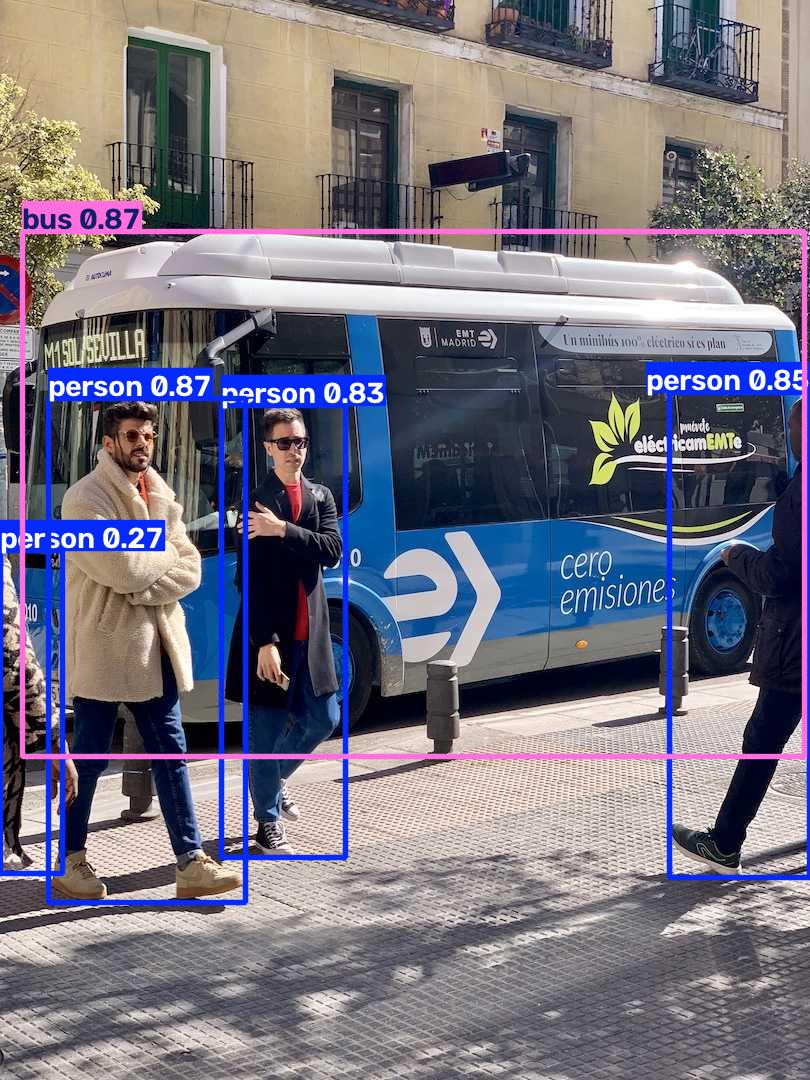

In [4]:
from collections import Counter
found = json.load(open("reports/day7_detections.json"))
print("picture:", found["image"])
print("model:  ", found["model"])
print("found:  ", dict(Counter(item["label"] for item in found["objects"])))
for item in found["objects"][:3]:
    print(item)

from IPython.display import Image, display
display(Image("reports/day7_detections.jpg", width=360))

## 4. Conclusion

- **Transfer learning did not win here.** The small CNN built for 28 by 28 pictures beat ResNet50 (0.877 vs 0.866 fine-tuned, 0.827 frozen). A likely reason (not tested) is that tiny grey pictures give ResNet50 little of the detail it learned on large colour photos. Fine-tuning helped (+0.039) but did not close the gap.
- **We have not tested on real catalog photos**, where transfer learning is expected to help. That needs the Kaggle dataset.
- **Detection works but is generic.** YOLO finds people and objects with boxes. To find *dress* or *shirt* it would need to be trained on fashion boxes.
- Single run, single seed: gaps of about 0.01 are noise.